c:\Users\mjlb1\venv311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Entrenando el modelo...
¡Entrenamiento completado exitosamente! Logs: logs\fit\20260916-153520

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
--- Reporte de Clasificación ---
              precision    recall  f1-score   support

   malignant       0.95      0.98      0.97        43
      benign       0.99      0.97      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114

--- Métricas Avanzadas ---
Área Bajo la Curva ROC (AUC): 0.9971
Indicador Gini:               0.9941



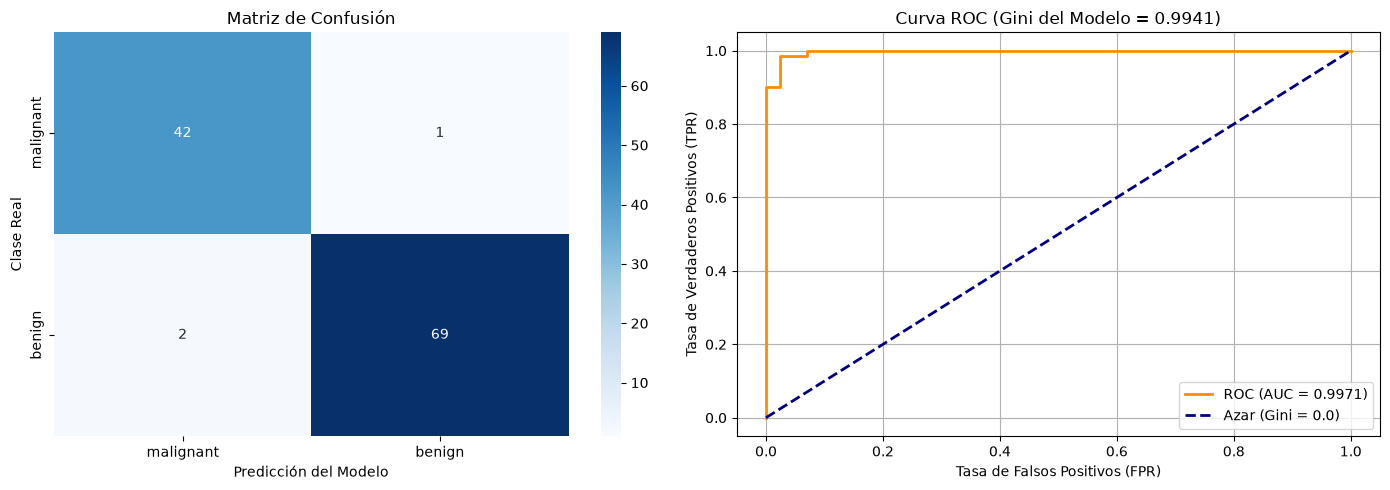

Calculando valores SHAP para explicar el modelo...


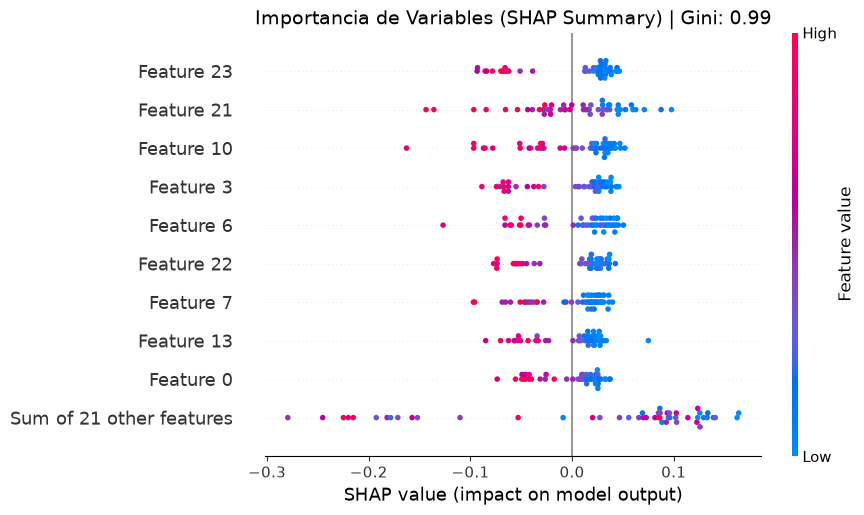

In [12]:
# ==============================================================================
# 1. IMPORTACIÓN DE LIBRERÍAS
# ==============================================================================
from datetime import datetime
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, roc_curve, auc, classification_report
import shap

# Evitar problemas de visualización de gráficos SHAP en Jupyter
shap.initjs()

# ==============================================================================
# 2. PREPARACIÓN DE DATOS (TRAIN / TEST)
# ==============================================================================
data = load_breast_cancer()
X, y = data.data, data.target

# División: 80% Entrenamiento y 20% Prueba (Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Escalado de características para la Red Neuronal
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==============================================================================
# 3. DISEÑO Y ENTRENAMIENTO DE LA RED NEURONAL (TERNSORFLOW)
# ==============================================================================
model = tf.keras.Sequential([
    tf.keras.layers.Dense(16, activation='relu', input_shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')  # Clasificación binaria
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Registrar métricas y grafo del modelo para TensorBoard
log_dir = Path("logs/fit") / datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard_callback = tf.keras.callbacks.TensorBoard(
    log_dir=str(log_dir), histogram_freq=1, profile_batch=0
)

print("Entrenando el modelo...")
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=60,
    batch_size=32,
    validation_split=0.1,
    callbacks=[tensorboard_callback],
    verbose=0,
)
print(f"¡Entrenamiento completado exitosamente! Logs: {log_dir}\n")

# ==============================================================================
# 4. PREDICCIONES Y CÁLCULO DE MÉTRICAS
# ==============================================================================
# Obtener probabilidades continuas y clases binarias (0 o 1)
y_pred_prob = model.predict(X_test_scaled).ravel()
y_pred = (y_pred_prob > 0.5).astype(int)

# Reporte de clasificación tradicional
print("--- Reporte de Clasificación ---")
print(classification_report(y_test, y_pred, target_names=data.target_names))

# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)

# Curva ROC y AUC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

# --- CÁLCULO DEL INDICADOR GINI ---
gini_index = (2 * roc_auc) - 1

print("--- Métricas Avanzadas ---")
print(f"Área Bajo la Curva ROC (AUC): {roc_auc:.4f}")
print(f"Indicador Gini:               {gini_index:.4f}\n")

# ==============================================================================
# 5. VISUALIZACIONES Y GRÁFICOS
# ==============================================================================
# Configurar ventana de gráficos para las métricas estándar
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico A: Matriz de Confusión Estilizada
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=data.target_names, yticklabels=data.target_names)
axes[0].set_title('Matriz de Confusión')
axes[0].set_xlabel('Predicción del Modelo')
axes[0].set_ylabel('Clase Real')

# Gráfico B: Curva ROC e indicación de Gini
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Azar (Gini = 0.0)')
axes[1].set_xlabel('Tasa de Falsos Positivos (FPR)')
axes[1].set_ylabel('Tasa de Verdaderos Positivos (TPR)')
axes[1].set_title(f'Curva ROC (Gini del Modelo = {gini_index:.4f})')
axes[1].legend(loc="lower right")
axes[1].grid(True)

plt.tight_layout()
plt.show()

# ==============================================================================
# 6. EXPLICABILIDAD GLOBAL CON SHAP
# ==============================================================================
print("Calculando valores SHAP para explicar el modelo...")
# Usamos un subset de entrenamiento como fondo neutral
explainer = shap.Explainer(model, X_train_scaled[:100])
# Evaluamos los primeros 50 registros del set de test
shap_values = explainer(X_test_scaled[:50])

# Graficar la importancia de las variables (Beeswarm plot)
plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.title(f"Importancia de Variables (SHAP Summary) | Gini: {gini_index:.2f}", fontsize=14)
plt.show()


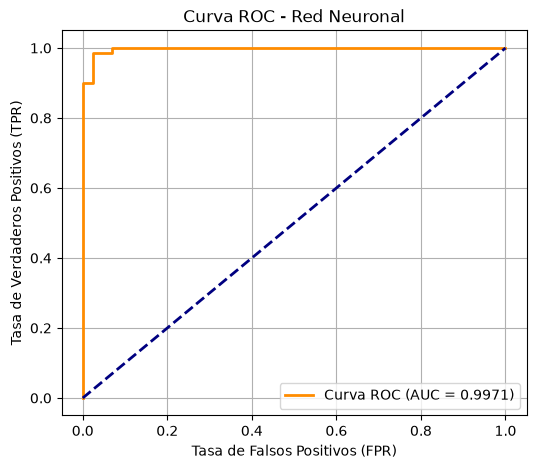

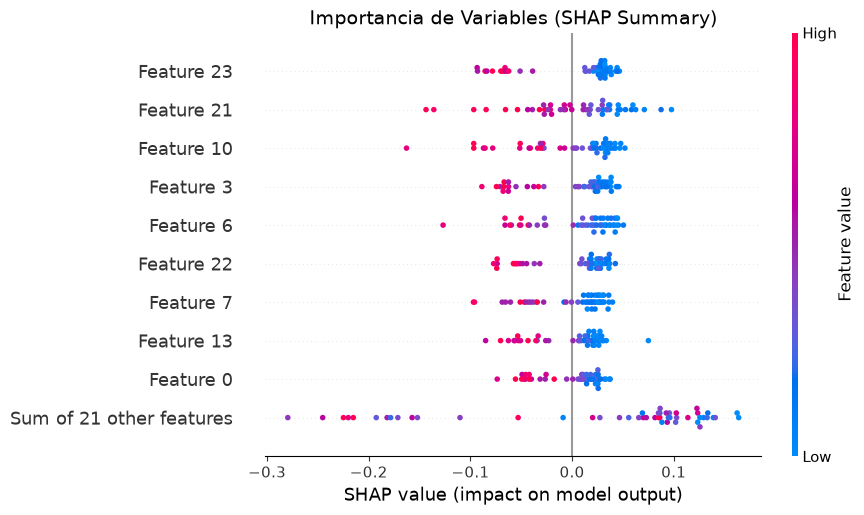

In [13]:
# Gráfico 1: Curva ROC
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC - Red Neuronal')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# Gráfico 2: SHAP Beeswarm Plot (Importancia de variables)
plt.title("Importancia de Variables (SHAP Summary)", fontsize=14)
shap.plots.beeswarm(shap_values, max_display=10)


In [14]:
# ==============================================================================
# 7. INTERFAZ WEB DE TENSORBOARD
# ==============================================================================
# Ejecutar esta celda después del entrenamiento para abrir TensorBoard en VS Code.
%load_ext tensorboard
%tensorboard --logdir logs/fit

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 27164), started 0:03:52 ago. (Use '!kill 27164' to kill it.)